# Exploratory Data Analysis (EDA) for Predictive Maintenance

The goal of this notebook is to analyze the AI4I 2020 Predictive Maintenance Dataset, identify mechanical patterns leading to equipment failure, and prepare the preprocessing strategy for our machine learning pipeline.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual theme
sns.set_theme(style="whitegrid")

# Load the raw dataset
df = pd.read_csv('../data/raw/ai4i2020.csv')
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 1. Class Imbalance Analysis
In real-world manufacturing, catastrophic failures are rare events. We need to visualize the distribution of functional versus defective states to determine if we need specific imbalance-handling techniques (like adjusting `scale_pos_weight` in XGBoost).

C:\Users\denis\AppData\Local\Temp\ipykernel_21192\3423433826.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Machine failure', palette='Set1')


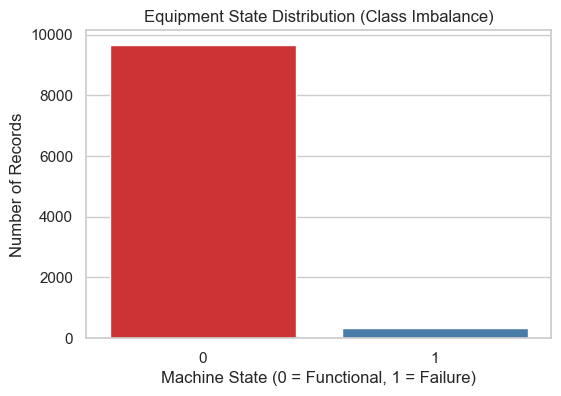

In [2]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Machine failure', palette='Set1')
plt.title('Equipment State Distribution (Class Imbalance)')
plt.xlabel('Machine State (0 = Functional, 1 = Failure)')
plt.ylabel('Number of Records')
plt.show()

## 2. Correlation and Data Leakage
Data leakage occurs when the model is trained with information that will not be available during real-time prediction. We will generate a correlation heatmap to identify if any columns act as "cheat codes" for the model.

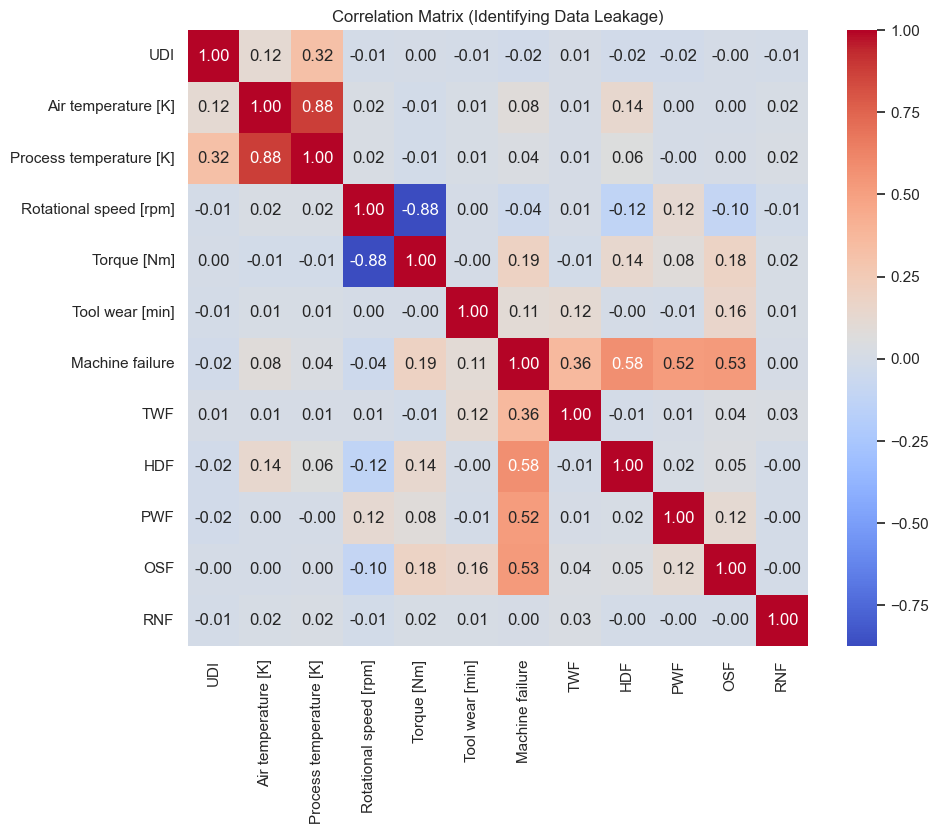

In [3]:
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_cols.corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title('Correlation Matrix (Identifying Data Leakage)')
plt.show()

> **Observation:** The columns `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` show strong correlations with `Machine failure`. These represent the specific *types* of failures logged by technicians after the event. If we leave them in the training set, the model will rely on these labels rather than learning the physical sensor patterns. They must be dropped before training.

## 3. Physical Thresholds and Mechanical Stress
We will visualize the interaction between different sensors (Torque vs. RPM, and Air vs. Process Temperature) to see if failures cluster in specific mechanical stress zones.

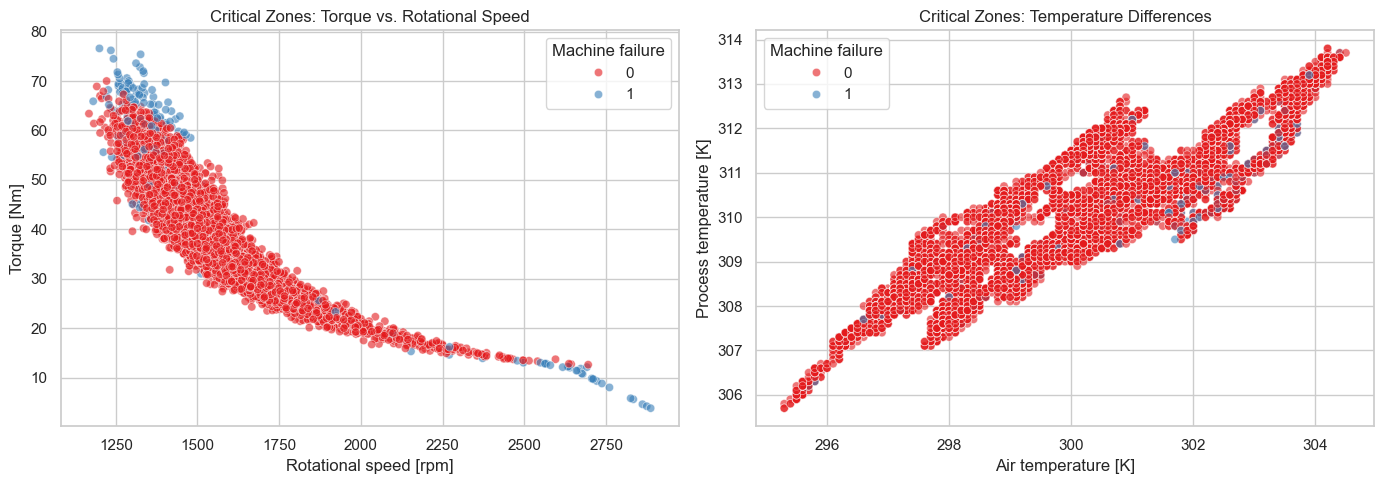

In [4]:
plt.figure(figsize=(14, 5))

# Torque vs. Rotational Speed
plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='Rotational speed [rpm]', y='Torque [Nm]', hue='Machine failure', alpha=0.6, palette='Set1')
plt.title('Critical Zones: Torque vs. Rotational Speed')

# Temperature Differentials
plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x='Air temperature [K]', y='Process temperature [K]', hue='Machine failure', alpha=0.6, palette='Set1')
plt.title('Critical Zones: Temperature Differences')

plt.tight_layout()
plt.show()

## 4. Impact of Part Quality
The dataset includes a categorical feature representing part quality: `L` (Low), `M` (Medium), and `H` (High). We will check if lower-quality parts have a statistically higher probability of causing equipment failure.

C:\Users\denis\AppData\Local\Temp\ipykernel_21192\3766630790.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Type', y='Machine failure', palette='viridis', order=['L', 'M', 'H'])


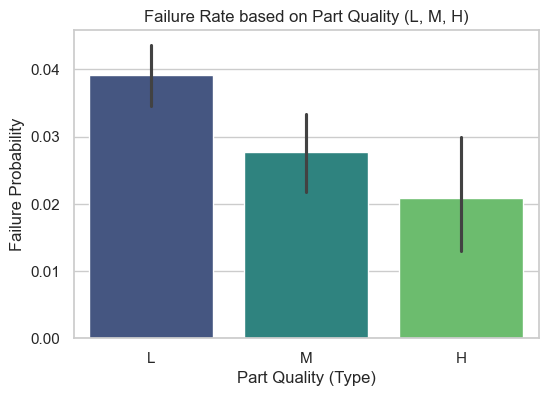

In [5]:
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x='Type', y='Machine failure', palette='viridis', order=['L', 'M', 'H'])
plt.title('Failure Rate based on Part Quality (L, M, H)')
plt.xlabel('Part Quality (Type)')
plt.ylabel('Failure Probability')
plt.show()